Shape: (4998, 141)


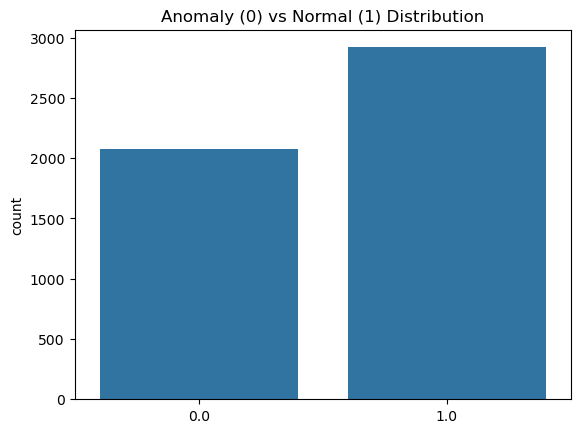

Normal Train Shape: (2328, 140)
Total Test Shape: (1000, 140)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0271 - mae: 0.1376 - val_loss: 0.0246 - val_mae: 0.1295
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0167 - mae: 0.1018 - val_loss: 0.0087 - val_mae: 0.0704
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0064 - mae: 0.0569 - val_loss: 0.0053 - val_mae: 0.0496
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0051 - mae: 0.0478 - val_loss: 0.0050 - val_mae: 0.0477
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0049 - mae: 0.0468 - val_loss: 0.0049 - val_mae: 0.0471
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0049 - mae: 0.0465 - val_loss: 0.0049 - val_mae: 0.0469
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0048 - mae: 0.0463 - val_loss: 0.0048 - val_mae: 0.0467
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0048 - mae: 0.0460 - val_loss: 0.0048 - val_mae: 0.0463
Epoch 9/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.004

In [ ]:
# Cell 1: Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Cell 2: Load and Explore Dataset
data = pd.read_csv("ecg.csv", header=None)
data.dropna(inplace=True)

print("Shape:", data.shape)

# Target column is the last one (1.0 = Normal, 0.0 = Anomaly)
target_col = data.columns[-1]
X = data.drop(target_col, axis=1).values
y = data[target_col].values

sns.countplot(x=y)
plt.title("Anomaly (0) vs Normal (1) Distribution")
plt.show()

# Cell 3: Train-Test Split & Scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Isolate ONLY normal heartbeats (1.0) for training
normal_train_data = X_train_scaled[y_train == 1]
normal_test_data  = X_test_scaled[y_test == 1]

print("Normal Train Shape:", normal_train_data.shape)
print("Total Test Shape:", X_test_scaled.shape)

# Cell 4: Build Autoencoder Model
input_dim = X_train_scaled.shape[1]

autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),

    # Bottleneck
    layers.Dense(8, activation="relu"),

    # Decoder
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),

    # Output
    layers.Dense(input_dim, activation="sigmoid")
])

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

autoencoder.summary()

# Cell 5: Train Model on Normal Data Only
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    normal_train_data, normal_train_data,
    epochs=50,
    batch_size=128,
    validation_data=(normal_test_data, normal_test_data),
    callbacks=[early_stopping],
    verbose=1
)

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

# Cell 6: Compute Reconstruction Threshold on Normal Training Data
normal_train_pred = autoencoder.predict(normal_train_data)
train_errors = np.mean(np.square(normal_train_data - normal_train_pred), axis=1)

threshold = np.mean(train_errors) + np.std(train_errors)
print("Reconstruction Threshold:", threshold)

# Compute reconstruction error across all test samples
X_test_pred = autoencoder.predict(X_test_scaled)
test_errors = np.mean(np.square(X_test_scaled - X_test_pred), axis=1)

# Cell 7: Evaluate Predictions
# Low error (< threshold) -> 1 (Normal); High error (>= threshold) -> 0 (Anomaly)
y_pred = [1 if e < threshold else 0 for e in test_errors]

acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (0 = Anomaly, 1 = Normal)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()